In [2]:
import os
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from tqdm import tqdm

from skimage.feature import local_binary_pattern, hog

from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline

from sklearn.model_selection import StratifiedKFold, cross_val_score

from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier, AdaBoostClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier

from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    f1_score
)

import warnings
warnings.filterwarnings("ignore")

In [3]:
BASE_DIR = r"D:\B. Disease Grading"

TRAIN_IMG_DIR = os.path.join(
    BASE_DIR,
    "1. Original Images",
    "a. Training Set"
)

TEST_IMG_DIR = os.path.join(
    BASE_DIR,
    "1. Original Images",
    "b. Testing Set"
)

GROUNDTRUTH_DIR = os.path.join(
    BASE_DIR,
    "2. Groundtruths"
)

print("Training images:", TRAIN_IMG_DIR)
print("Testing images :", TEST_IMG_DIR)
print("Groundtruths   :", GROUNDTRUTH_DIR)

print("\nTraining folder exists:", os.path.exists(TRAIN_IMG_DIR))
print("Testing folder exists :", os.path.exists(TEST_IMG_DIR))
print("Groundtruth exists    :", os.path.exists(GROUNDTRUTH_DIR))

Training images: D:\B. Disease Grading\1. Original Images\a. Training Set
Testing images : D:\B. Disease Grading\1. Original Images\b. Testing Set
Groundtruths   : D:\B. Disease Grading\2. Groundtruths

Training folder exists: True
Testing folder exists : True
Groundtruth exists    : True


In [4]:
for root, dirs, files in os.walk(GROUNDTRUTH_DIR):
    print("\nFolder:", root)
    
    for file in files:
        print("  ", file)


Folder: D:\B. Disease Grading\2. Groundtruths
   a. IDRiD_Disease Grading_Training Labels.csv
   b. IDRiD_Disease Grading_Testing Labels.csv


In [5]:
TRAIN_LABEL_FILE = os.path.join(
    GROUNDTRUTH_DIR,
    "a. IDRiD_Disease Grading_Training Labels.csv"
)

TEST_LABEL_FILE = os.path.join(
    GROUNDTRUTH_DIR,
    "b. IDRiD_Disease Grading_Testing Labels.csv"
)

In [6]:
train_df = pd.read_csv(TRAIN_LABEL_FILE)
test_df = pd.read_csv(TEST_LABEL_FILE)

print("Training labels:")
display(train_df.head())

print("\nTesting labels:")
display(test_df.head())

Training labels:


,Image name,Retinopathy grade,Risk of macular edema,Unnamed: 3,Unnamed: 4,Unnamed: 5,Unnamed: 6,Unnamed: 7,Unnamed: 8,Unnamed: 9,Unnamed: 10,Unnamed: 11
0,IDRiD_001,3,2,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,IDRiD_002,3,2,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,IDRiD_003,2,2,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,IDRiD_004,3,2,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,IDRiD_005,4,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN



Testing labels:


,Image name,Retinopathy grade,Risk of macular edema
0,IDRiD_001,4,0
1,IDRiD_002,4,1
2,IDRiD_003,4,0
3,IDRiD_004,4,0
4,IDRiD_005,4,1


In [7]:
print(train_df.columns)
print(test_df.columns)

Index(['Image name', 'Retinopathy grade', 'Risk of macular edema ',
       'Unnamed: 3', 'Unnamed: 4', 'Unnamed: 5', 'Unnamed: 6', 'Unnamed: 7',
       'Unnamed: 8', 'Unnamed: 9', 'Unnamed: 10', 'Unnamed: 11'],
      dtype='object')
Index(['Image name', 'Retinopathy grade', 'Risk of macular edema '], dtype='object')


In [8]:
print("TRAINING CLASS DISTRIBUTION")
print(train_df["Retinopathy grade"].value_counts().sort_index())

print("\nTRAINING CLASS PERCENTAGE")
print(
    train_df["Retinopathy grade"]
    .value_counts(normalize=True)
    .sort_index()
    .mul(100)
    .round(2)
)

TRAINING CLASS DISTRIBUTION
Retinopathy grade
0    134
1     20
2    136
3     74
4     49
Name: count, dtype: int64

TRAINING CLASS PERCENTAGE
Retinopathy grade
0    32.45
1     4.84
2    32.93
3    17.92
4    11.86
Name: proportion, dtype: float64


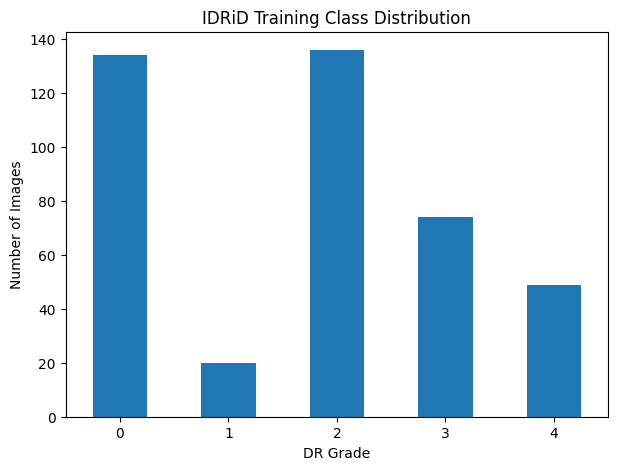

In [9]:
plt.figure(figsize=(7, 5))

train_df["Retinopathy grade"].value_counts().sort_index().plot(
    kind="bar"
)

plt.xlabel("DR Grade")
plt.ylabel("Number of Images")
plt.title("IDRiD Training Class Distribution")
plt.xticks(rotation=0)
plt.show()

In [10]:
def create_image_mapping(image_dir):
    
    image_mapping = {}
    
    for file in os.listdir(image_dir):
        
        if file.lower().endswith((".jpg", ".jpeg", ".png", ".tif", ".tiff")):
            
            image_id = os.path.splitext(file)[0]
            image_mapping[image_id] = os.path.join(image_dir, file)
    
    return image_mapping


train_image_mapping = create_image_mapping(TRAIN_IMG_DIR)
test_image_mapping = create_image_mapping(TEST_IMG_DIR)

print("Training images found:", len(train_image_mapping))
print("Testing images found :", len(test_image_mapping))

Training images found: 413
Testing images found : 103


In [11]:
def prepare_dataframe(df, image_mapping):
    
    data = df.copy()
    
    data["image_path"] = data["Image name"].map(image_mapping)
    
    missing = data["image_path"].isna().sum()
    
    print("Total records:", len(data))
    print("Missing images:", missing)
    
    return data


train_data = prepare_dataframe(
    train_df,
    train_image_mapping
)

test_data = prepare_dataframe(
    test_df,
    test_image_mapping
)
print(train_data.head())

Total records: 413
Missing images: 0
Total records: 103
Missing images: 0
  Image name  Retinopathy grade  Risk of macular edema   Unnamed: 3  \
0  IDRiD_001                  3                       2         NaN   
1  IDRiD_002                  3                       2         NaN   
2  IDRiD_003                  2                       2         NaN   
3  IDRiD_004                  3                       2         NaN   
4  IDRiD_005                  4                       0         NaN   

   Unnamed: 4  Unnamed: 5  Unnamed: 6  Unnamed: 7  Unnamed: 8  Unnamed: 9  \
0         NaN         NaN         NaN         NaN         NaN         NaN   
1         NaN         NaN         NaN         NaN         NaN         NaN   
2         NaN         NaN         NaN         NaN         NaN         NaN   
3         NaN         NaN         NaN         NaN         NaN         NaN   
4         NaN         NaN         NaN         NaN         NaN         NaN   

   Unnamed: 10 Unnamed: 11          

In [12]:
train_data = train_data.dropna(subset=["image_path"]).reset_index(drop=True)
test_data = test_data.dropna(subset=["image_path"]).reset_index(drop=True)

print("Final training samples:", len(train_data))
print("Final testing samples :", len(test_data))

Final training samples: 413
Final testing samples : 103


In [13]:
IMG_SIZE = (256, 256)
def preprocess_image(image_path):
    
    image = cv2.imread(image_path)
    
    if image is None:
        raise ValueError(f"Could not read image: {image_path}")
    
    # Resize
    image = cv2.resize(
        image,
        IMG_SIZE,
        interpolation=cv2.INTER_AREA
    )
    
    # Convert BGR → grayscale
    gray = cv2.cvtColor(
        image,
        cv2.COLOR_BGR2GRAY
    )
    
    # Histogram normalization
    gray = cv2.equalizeHist(gray)
    
    # Normalize pixel intensity to [0, 1]
    gray = gray.astype(np.float32) / 255.0
    
    return gray

Image shape: (256, 256)
Minimum: 0.0
Maximum: 1.0


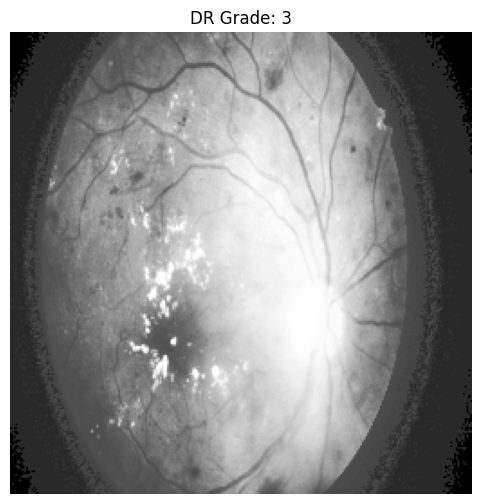

In [14]:
sample_path = train_data.iloc[0]["image_path"]

sample_image = preprocess_image(sample_path)

print("Image shape:", sample_image.shape)
print("Minimum:", sample_image.min())
print("Maximum:", sample_image.max())
plt.figure(figsize=(6, 6))

plt.imshow(sample_image, cmap="gray")
plt.title(
    f"DR Grade: {train_data.iloc[0]['Retinopathy grade']}"
)
plt.axis("off")

plt.show()

In [15]:
def extract_bpp(image, radius=1, n_points=8, levels=3):
    
    bpp_features = []
    
    # LBP
    lbp = local_binary_pattern(
        image,
        n_points,
        radius,
        method="uniform"
    )
    
    # Number of histogram bins for uniform LBP
    n_bins = n_points + 2
    
    height, width = image.shape
    
    for level in range(levels):
        
        num_regions = 2 ** level
        
        region_height = height // num_regions
        region_width = width // num_regions
        
        for row in range(num_regions):
            
            for col in range(num_regions):
                
                y_start = row * region_height
                y_end = (row + 1) * region_height
                
                x_start = col * region_width
                x_end = (col + 1) * region_width
                
                region = lbp[
                    y_start:y_end,
                    x_start:x_end
                ]
                
                histogram, _ = np.histogram(
                    region.ravel(),
                    bins=np.arange(n_bins + 1),
                    range=(0, n_bins),
                    density=True
                )
                
                # L1 normalization
                histogram = histogram / (
                    histogram.sum() + 1e-8
                )
                
                bpp_features.extend(histogram)
    
    return np.array(bpp_features, dtype=np.float32)

In [16]:
bpp = extract_bpp(sample_image)

print("BPP feature shape:", bpp.shape)

BPP feature shape: (210,)


In [17]:
def extract_phog(
    image,
    orientations=9,
    pixels_per_cell=(16, 16),
    cells_per_block=(2, 2),
    levels=3
):
    
    phog_features = []
    
    height, width = image.shape
    
    for level in range(levels):
        
        num_regions = 2 ** level
        
        region_height = height // num_regions
        region_width = width // num_regions
        
        for row in range(num_regions):
            
            for col in range(num_regions):
                
                y_start = row * region_height
                y_end = (row + 1) * region_height
                
                x_start = col * region_width
                x_end = (col + 1) * region_width
                
                region = image[
                    y_start:y_end,
                    x_start:x_end
                ]
                
                # HOG for this pyramid region
                features = hog(
                    region,
                    orientations=orientations,
                    pixels_per_cell=pixels_per_cell,
                    cells_per_block=cells_per_block,
                    block_norm="L2-Hys",
                    feature_vector=True
                )
                
                phog_features.extend(features)
    
    return np.array(phog_features, dtype=np.float32)

In [18]:
phog = extract_phog(sample_image)

print("PHOG feature shape:", phog.shape)

PHOG feature shape: (20340,)


In [19]:
combined_features = np.concatenate([
    bpp,
    phog
])

print("BPP features :", len(bpp))
print("PHOG features:", len(phog))
print("Total features:", len(combined_features))

BPP features : 210
PHOG features: 20340
Total features: 20550


In [20]:
def extract_features(image_path):
    
    image = preprocess_image(image_path)
    
    bpp_features = extract_bpp(image)
    
    phog_features = extract_phog(image)
    
    combined = np.concatenate([
        bpp_features,
        phog_features
    ])
    
    return combined

In [21]:
def build_feature_matrix(dataframe, dataset_name="Dataset"):
    
    features = []
    labels = []
    
    print(f"\nExtracting features from {dataset_name}...")
    
    for _, row in tqdm(
        dataframe.iterrows(),
        total=len(dataframe)
    ):
        
        try:
            
            # Extract BPP + PHOG features
            feature_vector = extract_features(
                row["image_path"]
            )
            
            features.append(feature_vector)
            
            # Use Retinopathy grade as the target
            labels.append(
                int(row["Retinopathy grade"])
            )
            
        except Exception as e:
            
            print(
                f"\nError processing {row['Image name']}: {e}"
            )
    
    X = np.array(
        features,
        dtype=np.float32
    )
    
    y = np.array(
        labels,
        dtype=np.int64
    )
    
    return X, y

In [22]:
X_train, y_train = build_feature_matrix(
    train_data,
    "Training Set"
)

print("\nX_train shape:", X_train.shape)
print("y_train shape:", y_train.shape)


Extracting features from Training Set...


100%|██████████| 413/413 [02:21<00:00,  2.91it/s]


X_train shape: (413, 20550)
y_train shape: (413,)


In [23]:
print("Unique DR grades:")
print(np.unique(y_train))

Unique DR grades:
[0 1 2 3 4]


In [24]:
print("\nTraining class distribution:")

for grade in sorted(np.unique(y_train)):
    
    count = np.sum(y_train == grade)
    
    print(
        f"Grade {grade}: {count} images"
    )


Training class distribution:
Grade 0: 134 images
Grade 1: 20 images
Grade 2: 136 images
Grade 3: 74 images
Grade 4: 49 images


In [25]:
X_test, y_test = build_feature_matrix(
    test_data,
    "Testing Set"
)

print("\nTesting feature matrix shape:")
print(X_test.shape)

print("\nTesting labels shape:")
print(y_test.shape)


Extracting features from Testing Set...


100%|██████████| 103/103 [00:27<00:00,  3.77it/s]


Testing feature matrix shape:
(103, 20550)

Testing labels shape:
(103,)


In [26]:
print("Unique test grades:")
print(np.unique(y_test))

Unique test grades:
[0 1 2 3 4]


In [27]:
print("X_train:", X_train.shape)
print("X_test :", X_test.shape)

print("Number of training features:", X_train.shape[1])
print("Number of testing features :", X_test.shape[1])

X_train: (413, 20550)
X_test : (103, 20550)
Number of training features: 20550
Number of testing features : 20550


In [28]:
np.save(
    "X_train_BPP_PHOG.npy",
    X_train
)

np.save(
    "y_train_BPP_PHOG.npy",
    y_train
)

np.save(
    "X_test_BPP_PHOG.npy",
    X_test
)

np.save(
    "y_test_BPP_PHOG.npy",
    y_test
)

print("Features saved successfully!")

Features saved successfully!


In [32]:
from sklearn.model_selection import StratifiedKFold

cv = StratifiedKFold(
    n_splits=10,
    shuffle=True,
    random_state=42
)
svm_model = Pipeline([
    
    (
        "scaler",
        StandardScaler()
    ),
    
    (
        "classifier",
        SVC(
            kernel="rbf",
            C=1.0,
            gamma="scale"
        )
    )
])

In [33]:
svm_scores = cross_val_score(
    svm_model,
    X_train,
    y_train,
    cv=cv,
    scoring="accuracy",
    n_jobs=-1
)

In [34]:
print("SVM — 10-Fold Cross Validation")
print("=" * 45)

for i, score in enumerate(
    svm_scores,
    start=1
):
    
    print(
        f"Fold {i}: "
        f"{score * 100:.2f}%"
    )

print("=" * 45)

print(
    f"Mean Accuracy: "
    f"{svm_scores.mean() * 100:.2f}%"
)

print(
    f"Standard Deviation: "
    f"{svm_scores.std() * 100:.2f}%"
)

SVM — 10-Fold Cross Validation
Fold 1: 45.24%
Fold 2: 42.86%
Fold 3: 38.10%
Fold 4: 29.27%
Fold 5: 43.90%
Fold 6: 34.15%
Fold 7: 43.90%
Fold 8: 48.78%
Fold 9: 36.59%
Fold 10: 39.02%
Mean Accuracy: 40.18%
Standard Deviation: 5.55%


In [35]:
from sklearn.ensemble import RandomForestClassifier

rf_model = Pipeline([
    
    ("scaler", StandardScaler()),
    
    ("classifier", RandomForestClassifier(
        n_estimators=300,
        random_state=42,
        class_weight="balanced",
        n_jobs=-1
    ))
])

In [37]:
rf_scores = cross_val_score(
    rf_model,
    X_train,
    y_train,
    cv=cv,
    scoring="accuracy",
    n_jobs=-1
)

print("Random Forest — 10-Fold Cross Validation")
print("=" * 50)

for i, score in enumerate(rf_scores, start=1):
    print(f"Fold {i}: {score * 100:.2f}%")

print("=" * 50)

print(
    f"Mean Accuracy: "
    f"{rf_scores.mean() * 100:.2f}%"
)

print(
    f"Standard Deviation: "
    f"{rf_scores.std() * 100:.2f}%"
)

Random Forest — 10-Fold Cross Validation
Fold 1: 45.24%
Fold 2: 50.00%
Fold 3: 45.24%
Fold 4: 36.59%
Fold 5: 48.78%
Fold 6: 34.15%
Fold 7: 39.02%
Fold 8: 48.78%
Fold 9: 46.34%
Fold 10: 39.02%
Mean Accuracy: 43.32%
Standard Deviation: 5.36%


In [38]:
from sklearn.neighbors import KNeighborsClassifier

knn_model = Pipeline([
    
    ("scaler", StandardScaler()),
    
    ("classifier", KNeighborsClassifier(
        n_neighbors=5,
        metric="euclidean"
    ))
])
knn_scores = cross_val_score(
    knn_model,
    X_train,
    y_train,
    cv=cv,
    scoring="accuracy",
    n_jobs=-1
)

print("KNN — 10-Fold Cross Validation")
print("=" * 50)

for i, score in enumerate(knn_scores, start=1):
    print(f"Fold {i}: {score * 100:.2f}%")

print("=" * 50)

print(
    f"Mean Accuracy: "
    f"{knn_scores.mean() * 100:.2f}%"
)

print(
    f"Standard Deviation: "
    f"{knn_scores.std() * 100:.2f}%"
)

KNN — 10-Fold Cross Validation
Fold 1: 38.10%
Fold 2: 42.86%
Fold 3: 40.48%
Fold 4: 39.02%
Fold 5: 29.27%
Fold 6: 46.34%
Fold 7: 46.34%
Fold 8: 43.90%
Fold 9: 36.59%
Fold 10: 34.15%
Mean Accuracy: 39.70%
Standard Deviation: 5.19%


In [39]:
from sklearn.naive_bayes import GaussianNB

nb_model = Pipeline([
    
    ("scaler", StandardScaler()),
    
    ("classifier", GaussianNB())
])
nb_scores = cross_val_score(
    nb_model,
    X_train,
    y_train,
    cv=cv,
    scoring="accuracy",
    n_jobs=-1
)

print("Naive Bayes — 10-Fold Cross Validation")
print("=" * 50)

for i, score in enumerate(nb_scores, start=1):
    print(f"Fold {i}: {score * 100:.2f}%")

print("=" * 50)

print(
    f"Mean Accuracy: "
    f"{nb_scores.mean() * 100:.2f}%"
)

print(
    f"Standard Deviation: "
    f"{nb_scores.std() * 100:.2f}%"
)

Naive Bayes — 10-Fold Cross Validation
Fold 1: 23.81%
Fold 2: 28.57%
Fold 3: 33.33%
Fold 4: 31.71%
Fold 5: 26.83%
Fold 6: 21.95%
Fold 7: 43.90%
Fold 8: 19.51%
Fold 9: 24.39%
Fold 10: 19.51%
Mean Accuracy: 27.35%
Standard Deviation: 7.10%


In [40]:
from sklearn.linear_model import LogisticRegression

lr_model = Pipeline([
    
    ("scaler", StandardScaler()),
    
    ("classifier", LogisticRegression(
        max_iter=3000,
        class_weight="balanced",
        random_state=42
    ))
])
lr_scores = cross_val_score(
    lr_model,
    X_train,
    y_train,
    cv=cv,
    scoring="accuracy",
    n_jobs=-1
)

print("Logistic Regression — 10-Fold Cross Validation")
print("=" * 50)

for i, score in enumerate(lr_scores, start=1):
    print(f"Fold {i}: {score * 100:.2f}%")

print("=" * 50)

print(
    f"Mean Accuracy: "
    f"{lr_scores.mean() * 100:.2f}%"
)

print(
    f"Standard Deviation: "
    f"{lr_scores.std() * 100:.2f}%"
)

Logistic Regression — 10-Fold Cross Validation
Fold 1: 54.76%
Fold 2: 40.48%
Fold 3: 45.24%
Fold 4: 41.46%
Fold 5: 34.15%
Fold 6: 43.90%
Fold 7: 48.78%
Fold 8: 51.22%
Fold 9: 41.46%
Fold 10: 39.02%
Mean Accuracy: 44.05%
Standard Deviation: 5.83%


In [43]:
from sklearn.tree import DecisionTreeClassifier

dt_model = Pipeline([
    
    ("scaler", StandardScaler()),
    
    ("classifier", DecisionTreeClassifier(
        criterion="entropy",
        random_state=42,
        class_weight="balanced"
    ))
])
from sklearn.tree import DecisionTreeClassifier

dt_model = Pipeline([
    
    ("scaler", StandardScaler()),
    
    ("classifier", DecisionTreeClassifier(
        criterion="entropy",
        random_state=42,
        class_weight="balanced"
    ))
])
dt_scores = cross_val_score(
    dt_model,
    X_train,
    y_train,
    cv=cv,
    scoring="accuracy",
    n_jobs=-1
)

print("Decision Tree — 10-Fold Cross Validation")
print("=" * 50)

for i, score in enumerate(dt_scores, start=1):
    print(f"Fold {i}: {score * 100:.2f}%")

print("=" * 50)

print(
    f"Mean Accuracy: "
    f"{dt_scores.mean() * 100:.2f}%"
)

print(
    f"Standard Deviation: "
    f"{dt_scores.std() * 100:.2f}%"
)

Decision Tree — 10-Fold Cross Validation
Fold 1: 28.57%
Fold 2: 30.95%
Fold 3: 28.57%
Fold 4: 39.02%
Fold 5: 36.59%
Fold 6: 34.15%
Fold 7: 41.46%
Fold 8: 34.15%
Fold 9: 26.83%
Fold 10: 26.83%
Mean Accuracy: 32.71%
Standard Deviation: 4.92%


In [44]:
from sklearn.ensemble import AdaBoostClassifier

adaboost_model = Pipeline([
    
    ("scaler", StandardScaler()),
    
    ("classifier", AdaBoostClassifier(
        estimator=DecisionTreeClassifier(
            max_depth=1,
            random_state=42
        ),
        n_estimators=100,
        random_state=42
    ))
])
ada_scores = cross_val_score(
    adaboost_model,
    X_train,
    y_train,
    cv=cv,
    scoring="accuracy",
    n_jobs=-1
)

print("AdaBoost — 10-Fold Cross Validation")
print("=" * 50)

for i, score in enumerate(ada_scores, start=1):
    print(f"Fold {i}: {score * 100:.2f}%")

print("=" * 50)

print(
    f"Mean Accuracy: "
    f"{ada_scores.mean() * 100:.2f}%"
)

print(
    f"Standard Deviation: "
    f"{ada_scores.std() * 100:.2f}%"
)

AdaBoost — 10-Fold Cross Validation
Fold 1: 42.86%
Fold 2: 52.38%
Fold 3: 57.14%
Fold 4: 48.78%
Fold 5: 48.78%
Fold 6: 43.90%
Fold 7: 34.15%
Fold 8: 41.46%
Fold 9: 39.02%
Fold 10: 46.34%
Mean Accuracy: 45.48%
Standard Deviation: 6.34%


In [45]:
print("TRAINING CLASS DISTRIBUTION")
print("=" * 45)

for grade in range(5):
    
    count = np.sum(y_train == grade)
    
    percentage = count / len(y_train) * 100
    
    print(
        f"Grade {grade}: "
        f"{count} images "
        f"({percentage:.2f}%)"
    )

TRAINING CLASS DISTRIBUTION
Grade 0: 134 images (32.45%)
Grade 1: 20 images (4.84%)
Grade 2: 136 images (32.93%)
Grade 3: 74 images (17.92%)
Grade 4: 49 images (11.86%)


In [47]:
from sklearn.decomposition import PCA
svm_pca_model = Pipeline([
    
    (
        "scaler",
        StandardScaler()
    ),
    
    (
        "pca",
        PCA(
            n_components=0.95,
            random_state=42
        )
    ),
    
    (
        "classifier",
        SVC(
            kernel="rbf",
            C=1.0,
            gamma="scale"
        )
    )
])
svm_pca_scores = cross_val_score(
    svm_pca_model,
    X_train,
    y_train,
    cv=cv,
    scoring="accuracy",
    n_jobs=-1
)

print("PCA + SVM — 10-Fold CV")
print("=" * 45)

for i, score in enumerate(
    svm_pca_scores,
    start=1
):
    
    print(
        f"Fold {i}: "
        f"{score * 100:.2f}%"
    )

print("=" * 45)

print(
    f"Mean Accuracy: "
    f"{svm_pca_scores.mean() * 100:.2f}%"
)

print(
    f"Std: "
    f"{svm_pca_scores.std() * 100:.2f}%"
)

PCA + SVM — 10-Fold CV
Fold 1: 47.62%
Fold 2: 42.86%
Fold 3: 42.86%
Fold 4: 29.27%
Fold 5: 39.02%
Fold 6: 39.02%
Fold 7: 43.90%
Fold 8: 51.22%
Fold 9: 36.59%
Fold 10: 39.02%
Mean Accuracy: 41.14%
Std: 5.76%


In [48]:
pca_values = [
    0.80,
    0.90,
    0.95,
    0.99
]
pca_results = []

for variance in pca_values:
    
    print(
        f"\nTesting PCA variance = {variance}"
    )
    
    model = Pipeline([
        
        (
            "scaler",
            StandardScaler()
        ),
        
        (
            "pca",
            PCA(
                n_components=variance,
                random_state=42
            )
        ),
        
        (
            "classifier",
            SVC(
                kernel="rbf",
                C=1.0,
                gamma="scale"
            )
        )
    ])
    
    scores = cross_val_score(
        model,
        X_train,
        y_train,
        cv=cv,
        scoring="accuracy",
        n_jobs=-1
    )
    
    pca_results.append({
        "PCA Variance": variance,
        "Mean Accuracy (%)": scores.mean() * 100,
        "Std (%)": scores.std() * 100
    })
    pca_results_df = pd.DataFrame(
    pca_results
)

pca_results_df[
    "Mean Accuracy (%)"
] = pca_results_df[
    "Mean Accuracy (%)"
].round(2)

pca_results_df[
    "Std (%)"
] = pca_results_df[
    "Std (%)"
].round(2)

display(pca_results_df)


Testing PCA variance = 0.8

Testing PCA variance = 0.9

Testing PCA variance = 0.95

Testing PCA variance = 0.99


,PCA Variance,Mean Accuracy (%),Std (%)
0,0.80,41.16,4.63
1,0.90,41.63,5.79
2,0.95,41.14,5.76
3,0.99,41.14,5.66


In [49]:
svm_balanced = Pipeline([
    
    (
        "scaler",
        StandardScaler()
    ),
    
    (
        "classifier",
        SVC(
            kernel="rbf",
            C=1.0,
            gamma="scale",
            class_weight="balanced"
        )
    )
])
svm_balanced_scores = cross_val_score(
    svm_balanced,
    X_train,
    y_train,
    cv=cv,
    scoring="accuracy",
    n_jobs=-1
)

print("Balanced SVM — 10-Fold Cross Validation")
print("=" * 50)

for i, score in enumerate(
    svm_balanced_scores,
    start=1
):
    print(
        f"Fold {i}: "
        f"{score * 100:.2f}%"
    )

print("=" * 50)

print(
    f"Mean Accuracy: "
    f"{svm_balanced_scores.mean() * 100:.2f}%"
)

print(
    f"Standard Deviation: "
    f"{svm_balanced_scores.std() * 100:.2f}%"
)

Balanced SVM — 10-Fold Cross Validation
Fold 1: 33.33%
Fold 2: 38.10%
Fold 3: 33.33%
Fold 4: 36.59%
Fold 5: 24.39%
Fold 6: 41.46%
Fold 7: 56.10%
Fold 8: 36.59%
Fold 9: 39.02%
Fold 10: 34.15%
Mean Accuracy: 37.31%
Standard Deviation: 7.64%


In [51]:
svm_macro_scores = cross_val_score(
    svm_balanced,
    X_train,
    y_train,
    cv=cv,
    scoring="f1_macro",
    n_jobs=-1
)

print(
    f"Mean Macro F1: "
    f"{svm_macro_scores.mean():.4f}"
)

print(
    f"Std Macro F1: "
    f"{svm_macro_scores.std():.4f}"
)

Mean Macro F1: 0.2699
Std Macro F1: 0.0676
